In [30]:
#imports
import sys
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit, train_test_split
import time, platform, os
from sklearn.metrics import roc_auc_score,roc_curve
import matplotlib.pyplot as plt
import time

In [21]:
#PartB(b) Audit table
SEED = 4371
TARGET_FPR = 0.01

CONFIG = {
    "PhiUSIIL": dict(path="PhiUSIIL_result.csv",
                     label_col="label", phish_value=0,
                     group_col="Domain",
                     id_cols=["FILENAME", "URL", "Domain", "TLD", "Title"]),
    "UCI":      dict(path="UCILL_result.csv",
                     label_col="Result", phish_value=-1,
                     group_col=None, id_cols=["id"]),
    "Mendeley": dict(path="Mendeley_dataset.csv",
                     label_col="CLASS_LABEL", phish_value=1,
                     group_col=None, id_cols=["id"]),
}

In [22]:
def bucket_len(s):      # numeric URL length= 0 for short, 1 for medium, 2 for long
    return pd.cut(s, [-np.inf, 53, 75, np.inf], labels=[0, 1, 2]).astype(float)

def bucket_sub(s):      # number of subdomains= 0, 1, 2+
    return s.clip(upper=2).astype(float)

TRANSFORMS = {
    "PhiUSIIL": lambda d: pd.DataFrame({
        "ip_in_host":       d["IsDomainIP"].astype(float),
        "url_len_bucket":   bucket_len(d["URLLength"]),
        "subdomain_bucket": bucket_sub(d["NoOfSubDomain"])}),
    "UCI": lambda d: pd.DataFrame({
        "ip_in_host":       (d["having_IP_Address"] == -1).astype(float),
        "url_len_bucket":   d["URL_Length"].map({1: 0, 0: 1, -1: 2}),
        "subdomain_bucket": d["having_Sub_Domain"].map({1: 0, 0: 1, -1: 2})}),
    "Mendeley": lambda d: pd.DataFrame({
        "ip_in_host":       d["IpAddress"].astype(float),
        "url_len_bucket":   bucket_len(d["UrlLength"]),
        "subdomain_bucket": bucket_sub(d["SubdomainLevel"])}),
}
SHARED = ["ip_in_host", "url_len_bucket", "subdomain_bucket"]


In [23]:
#load, split, and threshold
DUPS = {}

def load(name):
    c = CONFIG[name]
    df = pd.read_csv(c["path"])
    print(f"\n[{name}] loaded {df.shape}; label values:",
          df[c["label_col"]].value_counts().to_dict())

    raw = [x for x in df.columns if x != c["label_col"] and x not in c["id_cols"]]
    n0 = len(df)
    df = df.drop_duplicates(subset=raw + [c["label_col"]])
    DUPS[name] = n0 - len(df)
    print(f"[{name}] exact duplicates removed: {DUPS[name]}")

    out = TRANSFORMS[name](df)
    out["label"] = (df[c["label_col"]] == c["phish_value"]).astype(int)
    out["group"] = df[c["group_col"]] if c["group_col"] else df.index
    out["dataset"] = name
    out["row_id"] = name + "_" + df.index.astype(str)
    out["rawkey"] = pd.util.hash_pandas_object(df[raw], index=False).values

    bad = out[SHARED].isna().any(axis=1)
    if bad.any():
        print(f"[{name}] dropping {int(bad.sum())} rows with unmapped shared-feature values")
    out = out[~bad].reset_index(drop=True)
    print(f"[{name}] kept {len(out)} rows; phishing share {out['label'].mean():.3f}")
    print(out[SHARED].describe().loc[["mean", "min", "max"]].round(3).to_string())
    return out


#primary-dataset split
def assign_primary_split(p, grouped):
    p = p.copy()
    idx = np.arange(len(p))
    if grouped:        # no group in two splits
        g1 = GroupShuffleSplit(1, test_size=0.30, random_state=SEED)
        tr, rest = next(g1.split(p, groups=p["group"]))
        r = p.iloc[rest]
        g2 = GroupShuffleSplit(1, test_size=0.50, random_state=SEED)
        va, te = next(g2.split(r, groups=r["group"]))
        va, te = rest[va], rest[te]
    else:              # stratified random on deduplicated rows
        tr, rest = train_test_split(idx, test_size=0.30, stratify=p["label"], random_state=SEED)
        va, te = train_test_split(rest, test_size=0.50, stratify=p["label"].iloc[rest],
                                  random_state=SEED)
    p["split"] = ""
    p.iloc[tr, p.columns.get_loc("split")] = "train"
    p.iloc[va, p.columns.get_loc("split")] = "validation"
    p.iloc[te, p.columns.get_loc("split")] = "test"
    return p


def pick_threshold(neg_scores, target_fpr):
    for t in np.unique(neg_scores):
        if (neg_scores >= t).mean() <= target_fpr:
            return float(t)
    return float(neg_scores.max()) + 1e-9


In [31]:
#full run for a chosen training dataset
def run(primary, data):
    d = {k: v.copy() for k, v in data.items()}
    d[primary] = assign_primary_split(d[primary], grouped=CONFIG[primary]["group_col"] is not None)
    for k in d:
        if k != primary:
            d[k]["split"] = "test"
    allrows = pd.concat(d.values(), ignore_index=True)
    allrows[["row_id", "dataset", "split", "label"]].to_csv(f"split_{primary}.csv", index=False)

    tr = allrows[(allrows.dataset == primary) & (allrows.split == "train")]
    va = allrows[(allrows.dataset == primary) & (allrows.split == "validation")]
    clf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                 random_state=SEED, n_jobs=-1)
    clf.fit(tr[SHARED], tr["label"])

    va_s = clf.predict_proba(va[SHARED])[:, 1]
    thr = pick_threshold(va_s[va["label"].to_numpy() == 0], TARGET_FPR)

    parts = []
    for name in CONFIG:
        t = allrows[(allrows.dataset == name) & (allrows.split == "test")]
        parts.append(pd.DataFrame({
            "row_id": t["row_id"],
            "test_set": f"{name} (in-dataset)" if name == primary else name,
            "label": t["label"],
            "score": clf.predict_proba(t[SHARED])[:, 1]}))
    pd.concat(parts).to_csv(f"scores_{primary}.csv", index=False)
    p = d[primary]
    print("exact duplicates removed per dataset:",
      {k: v.attrs.get("exact_dups_removed") for k, v in data.items()})
    if CONFIG[primary]["group_col"]:
        s = {sp: set(p.loc[p.split == sp, "group"]) for sp in ["train", "validation", "test"]}
        print("domains shared across splits (0):", len(s["train"] & s["validation"]), len(s["train"] & s["test"]), len(s["validation"] & s["test"]))
        reps = p["group"].value_counts()
        print("rows in repeated domains:", int(reps[reps > 1].sum()),
          "| domains:", reps.size)

    print(f"\n=== Train on {primary}: threshold {thr:.6f} ===")
    print(f"python check_checkpoint.py --split split_{primary}.csv "
          f"--scores scores_{primary}.csv --threshold {thr:.6f}")

    tr = allrows[(allrows.dataset == primary) & (allrows.split == "train")]
    va = allrows[(allrows.dataset == primary) & (allrows.split == "validation")]
    te = allrows[(allrows.dataset == primary) & (allrows.split == "test")]
    n2 = int(tr["rawkey"].isin(set(va["rawkey"])).sum())
    # (1a) train vs this dataset's own test set, same fields
    n1a = int(tr["rawkey"].isin(set(te["rawkey"])).sum())
    print(f"(2) train rows duplicating a validation row: {n2}")
    print(f"(1a) train rows duplicating a test row in {primary}: {n1a}")
    for other in CONFIG:
        if other == primary:
            continue
        ot = allrows[allrows.dataset == other][SHARED].drop_duplicates().assign(_hit=1)
        hit = tr[SHARED].merge(ot, on=SHARED, how="left")["_hit"].notna()
        print(f"(1b) train rows matching a {other} test row on shared features: "
          f"{int(hit.sum())} of {len(tr)} "
          f"({100 * hit.mean():.1f}%); distinct shared vectors in train: "
          f"{len(tr[SHARED].drop_duplicates())}")
    t0 = time.perf_counter()
    clf.fit(tr[SHARED], tr["label"])
    fit_s = time.perf_counter() - t0
    print(f"fit time: {fit_s:.1f} s | rows: {len(tr)} | cores: {os.cpu_count()} | {platform.processor() or platform.machine()}")

    #leakage check
    te = allrows[(allrows.dataset == primary) & (allrows.split == "test")].copy()
    te["score"] = clf.predict_proba(te[SHARED])[:, 1]
    flag = te["score"] >= thr
    print(f"[{primary}] flagged: {int(flag.sum())} | TP: {int((flag & (te.label == 1)).sum())} "
          f"| FP: {int((flag & (te.label == 0)).sum())} | test rows: {len(te)}")
    base = roc_auc_score(va["label"], clf.predict_proba(va[SHARED])[:, 1])
    for f in SHARED:
        cols = [c for c in SHARED if c != f]
        m = RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                   random_state=SEED, n_jobs=-1).fit(tr[cols], tr["label"])
        print(f"[{primary}] without {f}: validation AUROC "
              f"{roc_auc_score(va['label'], m.predict_proba(va[cols])[:, 1]):.4f} (all {base:.4f})")
    #run time check

    t0 = time.perf_counter(); clf.fit(tr[SHARED], tr["label"]); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); _ = clf.predict_proba(allrows[allrows.split == "test"][SHARED]); score_s = time.perf_counter() - t0
    print(f"fit {fit_s:.1f} s | scoring {score_s:.1f} s | training rows {len(tr)}")

if __name__ == "__main__":
    data = {n: load(n) for n in CONFIG}
    targets = [a for a in sys.argv[1:] if a in CONFIG] or list(CONFIG)
    for primary in targets:
        run(primary, data)


[PhiUSIIL] loaded (235795, 56); label values: {1: 134850, 0: 100945}
[PhiUSIIL] exact duplicates removed: 808
[PhiUSIIL] kept 234987 rows; phishing share 0.426
      ip_in_host  url_len_bucket  subdomain_bucket
mean       0.003           0.133             1.125
min        0.000           0.000             0.000
max        1.000           2.000             2.000

[UCI] loaded (11055, 32); label values: {1: 6157, -1: 4898}
[UCI] exact duplicates removed: 5206
[UCI] kept 5849 rows; phishing share 0.516
      ip_in_host  url_len_bucket  subdomain_bucket
mean       0.434           1.616             0.934
min        0.000           0.000             0.000
max        1.000           2.000             2.000

[Mendeley] loaded (10000, 50); label values: {1: 5000, 0: 5000}
[Mendeley] exact duplicates removed: 419
[Mendeley] kept 9581 rows; phishing share 0.479
      ip_in_host  url_len_bucket  subdomain_bucket
mean       0.016           0.975             0.544
min        0.000           0.000  

In [17]:
#count missing values
for name, (path, target) in {"PhiUSIIL": ("PhiUSIIL_result.csv", "label"),
                             "UCI": ("UCILL_result.csv", "Result"),
                             "Mendeley": ("Mendeley_dataset.csv", "CLASS_LABEL")}.items():
    df = pd.read_csv(path)
    s = df[target]
    print(name,
          "NaN:", int(s.isna().sum()),
          "| placeholders:", int(s.astype(str).str.strip().isin(["", "?", "NA", "nan"]).sum()),
          "| values:", sorted(s.dropna().unique().tolist()))



PhiUSIIL NaN: 0 | blank/placeholder strings: 0 | values seen: [0, 1]
UCI NaN: 0 | blank/placeholder strings: 0 | values seen: [-1, 1]
Mendeley NaN: 0 | blank/placeholder strings: 0 | values seen: [0, 1]


In [18]:
#duplicates/repeated
PATH      = "PhiUSIIL_result.csv"
label_col = "label"
id_cols   = ["FILENAME", "URL", "Domain", "TLD", "Title"]
domain_col = "Domain"

df  = pd.read_csv(PATH)
raw = [c for c in df.columns if c != label_col and c not in id_cols]

n_exact = int(df.duplicated(subset=raw + [label_col]).sum())
d = df.drop_duplicates(subset=raw + [label_col])
print("exact duplicates:", n_exact)

if domain_col:
    print("near-duplicates (same", domain_col, "beyond first):",
          int(d.duplicated(subset=[domain_col]).sum()))
else:
    def near_dups_hamming(X, k=1, chunk=500):
        X = X.to_numpy()
        rows = set()
        for i in range(0, len(X), chunk):
            diff = (X[i:i+chunk, None, :] != X[None, :, :]).sum(axis=2)
            for a in range(diff.shape[0]):
                j = np.where(diff[a] <= k)[0]
                if (j != i + a).any():
                    rows.add(i + a)
        return len(rows)

    print("rows with a near-duplicate partner (<=1 feature differs):",
          near_dups_hamming(d[raw]))

#repeated entities
counts   = d[domain_col].value_counts()
repeated = counts[counts > 1]

print("rows:", len(d))
print("unique", domain_col + "s:", counts.size)
print("entities appearing more than once:", len(repeated))
print("rows belonging to a repeated entity:", int(repeated.sum()),
      f"({100 * repeated.sum() / len(d):.2f}% of rows)")
print("largest entity:", counts.index[0], "with", int(counts.iloc[0]), "rows",
      f"({100 * counts.iloc[0] / len(d):.3f}% of rows)")
print("\ntop entities(10):\n", counts.head(10).to_string())

#one label or both
mix = d[d[domain_col].isin(repeated.index)].groupby(domain_col)[label_col].nunique()
print("\nrepeated entities with both labels:", int((mix > 1).sum()))

#date: no date/time/year/moth specified so no blank
print([c for c in df.columns if any(k in c.lower() for k in ["date", "time", "year", "month", "created", "timestamp"])])

for c in df.columns:
    if df[c].dtype == object:
        parsed = pd.to_datetime(df[c], errors="coerce")
        if parsed.notna().mean() > 0.9:
            print(c, parsed.min(), "to", parsed.max())

exact duplicates: 808
near-duplicates (same Domain beyond first): 15582
rows: 234987
unique Domains: 219405
entities appearing more than once: 5519
rows belonging to a repeated entity: 21101 (8.98% of rows)
largest entity: ipfs.io with 1197 rows (0.509% of rows)

top 10 entities:
 Domain
ipfs.io                         1197
docs.google.com                  526
mail.deliverylifesupport.com     370
cloudflare-ipfs.com              359
storageapi.fleek.co              318
gateway.pinata.cloud             275
gateway.ipfs.io                  249
ipfs.litnet.work                 223
cf-ipfs.com                      190
s3.amazonaws.com                 182

repeated entities with both labels: 54
[]


Caption: ROC curve of the baseline on the UCI test set (5,849 rows, 51.6% phishing).
Finding values: recall 90.1% at FPR 91.4%; AUROC 0.492


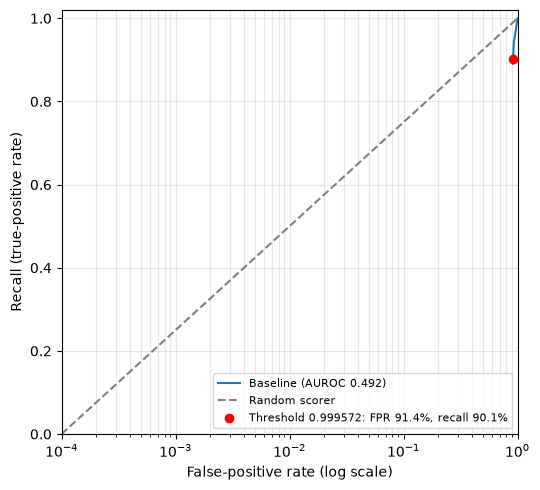

In [27]:
#Task 4
SCORES    = "scores_PhiUSIIL.csv"
TEST_SET  = "UCI"
THRESHOLD = 0.999572

g = pd.read_csv(SCORES).query("test_set == @TEST_SET")
y, s = g["label"].to_numpy(), g["score"].to_numpy()
n, pos = len(y), int(y.sum())

fpr, tpr, _ = roc_curve(y, s)
pred = s >= THRESHOLD
op_fpr, op_tpr = pred[y == 0].mean(), pred[y == 1].mean()
auc = roc_auc_score(y, s)

keep = fpr > 0
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr[keep], tpr[keep], label=f"Baseline (AUROC {auc:.3f})")
ax.plot([1e-4, 1], [1e-4, 1], "--", color="gray", label="Random scorer")
ax.scatter([max(op_fpr, 1e-4)], [op_tpr], color="red", zorder=3,
           label=f"Threshold {THRESHOLD:.6g}: FPR {op_fpr:.1%}, recall {op_tpr:.1%}")
ax.set_xscale("log"); ax.set_xlim(1e-4, 1); ax.set_ylim(0, 1.02)
ax.set_xlabel("False-positive rate (log scale)")
ax.set_ylabel("Recall (true-positive rate)")
ax.grid(alpha=0.3, which="both"); ax.legend(loc="lower right", fontsize=8)
fig.tight_layout(); fig.savefig("roc_baseline.png", dpi=200)

print(f"Caption: ROC curve of the baseline on the {TEST_SET} test set "
      f"({n:,} rows, {100*pos/n:.1f}% phishing).")
print(f"Finding values: recall {op_tpr:.1%} at FPR {op_fpr:.1%}; AUROC {auc:.3f}")

In [28]:
#5b
import re
lines = {
    "PhiUSIIL (in-dataset)": "0.2896 [0.2824, 0.2970]",
    "UCI": "0.9010 [0.8893, 0.9106]",
    "Mendeley": "0.8238 [0.8136, 0.8350]"
}
hw = {k: (float(b) - float(a)) / 2
      for k, v in lines.items()
      for a, b in [re.findall(r"\[(.+?), (.+?)\]", v)[0]]}
h = max(hw.values())
print(hw, "-> widest half-width:", round(h, 4))

{'PhiUSIIL (in-dataset)': 0.007300000000000001, 'UCI': 0.010649999999999993, 'Mendeley': 0.010699999999999987} -> widest half-width: 0.0107


In [32]:
#5c
measured = {
    "PhiUSIIL": (1.9, 0.1), #time from run
    "UCI":      (0.2, 0.3),
    "Mendeley": (0.2, 0.3),
}
checker_s = 20.0

done = ["PhiUSIIL"]         #non repeated run
remaining = [k for k in measured if k not in done]
total_s = sum(sum(measured[k]) + checker_s for k in remaining)
print(f"remaining runs: {remaining} -> {total_s/60:.1f} minutes (before margin)")

remaining runs: ['UCI', 'Mendeley'] -> 0.7 minutes (before margin)
